# The Second Corpus Study on German Nominal Compounding Constraints

## Background

German nominal compounding is a notoriously unpredictable and irregular process. About 40% of German N+N compounds insert a so-called linking element that is not confidently predictable for most of constituent classes. For example, nouns Birne ‘pear’ and Kirsche ‘cherry’ build compounds Birne-n-saft ‘pear juice’ but Kirsch-0-saft ‘cherry juice’ despite having nearly identical phonological, morphological, and semantic properties. The only linguistic generalizations available to gauge the correct linker are (mostly) irregular constraints that are eagerly violated.

Our first corpus study on German nominal compounding collected 64 constraints from the linguistic literature and verified 39 of them against ~280k German N+N compounds. The corpus study demonstrated that most of the constraints are irregular, indeed. The most crucial funding was that not all of the constraints were confirmed on the massive data. Specifically, 11 constraints were only partially supported by the data, and three were not supported at all.

The main limitation of the first corpus study was that none of the constraints involving semantic or lexical conditions could be implemented. The second version implements a couple of further constraints and runs the constraints on further datasets. Most importantly, fills in most of the gaps remaining after the first corpus study:
1. It implements 17 constraints involving semantics. Fourteen of the 17 constraints are pluralic constraints actively discussed in recent linguistics literature.
2. It applies more detailed statistic analyses to analyze relations between different ontological properties of the constraints (application manner, types of linguistic conditions etc.) and its coverage and regularity measures.
3. It additionally analyses constraints through the Yang 2016's Tolerance Principle lense and makes a first attempt to discriminate between linguistic constraints and statistical patterns, and to model compounding with the Elsewhere Condition.


## Datasets

```yaml
gecodb_v06:
    description: "~280k German N+N compounds from the DECOW16A corpus that are built from nouns found in CELEX2 and have a WC of at least 20 in DeReKo."
    origin: Originates from [Schäfer & Pankratz 2018](https://doi.org/10.5281/zenodo.1323211) (file 'linkingelements/Data/Database/compounds/decow16ax_comps_counts.txt'), first preprocessing(s) in [Shmalts BA Thesis](https://github.com/maxschmaltz/DEKOR), final preprocessing in [Shmalts 2026](https://lrec.elra.info/lrec2026-ws-slide-02).
    size: 282767 compound lemmata. 3614 N1 lemmata. 9 linkers, 11 linker allomorphs. 4768 unique N1+linker combinations.

gecodb_v07:
    description: "~275k German N+N compounds from the DECOW16A corpus that are built from nouns found in both CELEX2 and GermaNet and have a WC of at least 20 in DeReKo."
    origin: Originates from [Schäfer & Pankratz 2018](https://doi.org/10.5281/zenodo.1323211) (file 'linkingelements/Data/Database/compounds/decow16ax_comps_counts.txt'), first preprocessing(s) in [Shmalts BA Thesis](https://github.com/maxschmaltz/DEKOR) and [Shmalts 2026](https://lrec.elra.info/lrec2026-ws-slide-02), final preprocessing in the present study.
    size: 275411 compound lemmata. 3593 N1 lemmata. 10 linkers, 12 linker allomorphs. 4741 unique N1+linker combinations.

gecodb_v07_gn:
    description: "~49k German N+N compounds from the DECOW16A corpus that are built from nouns found in both CELEX2 and GermaNet, can themselves be parsed confidently in GermaNet, and have a WC of at least 20 in DeReKo."
    origin: Originates from [Schäfer & Pankratz 2018](https://doi.org/10.5281/zenodo.1323211) (file 'linkingelements/Data/Database/compounds/decow16ax_comps_counts.txt'), first preprocessing(s) in [Shmalts BA Thesis](https://github.com/maxschmaltz/DEKOR) and [Shmalts 2026](https://lrec.elra.info/lrec2026-ws-slide-02), final preprocessing in the present study.
    size: 48976 compound lemmata (48660 unique N1+N2 combinations). 3319 N1 lemmata. 10 linkers, 12 linker allomorphs. 3585 unique N1+linker combinations.

sp18_pl_constr:
    description: "~2.5k German N+N compounds from the DECOW16A corpus that have a WC of at least 20 in DeReKo, with annotated singular/plural meaning of N1."
    origin: Originates from [Schäfer & Pankratz 2018](https://doi.org/10.5281/zenodo.1323211) (file 'linkingelements/Data/Corpusstudy/Concordance.full.csv'), final preprocessing in the present study.
    size: 2681 compound lemmata. 44 N1 lemmata. 8 linkers, 9 linker allomorphs. 78 unique N1+(Sg/Pl meaning) combinations. 88 unique N1+linker combinations.
```


## Results

In [1]:
# project-level pwd
%cd ..

/Users/maksimshmalts/Documents/DieKonstraintsPrivat/semrel_comp_corp_study-private


In [2]:
import os
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
# from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import statsmodels.formula.api as smf
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.markers import MarkerStyle
from collections import Counter, defaultdict
from itertools import product, pairwise, combinations
import yaml
from typing import List, Tuple

from data_utils import load_datasets
from check_applicability.regularity_scale import REGULARITY_SCALE

In [3]:
constr_path = "constraints/constraints_all_revised.yaml"

appl_stat_dir = "out/constraints/applicability_statistics"
constr_stat_dir = "out/constraints/constraint_statistics/"

# os.makedirs(appl_stat_dir, exist_ok=True)
os.makedirs(constr_stat_dir, exist_ok=True)

In [4]:
save_tsv = lambda df, path: df.to_csv(
    path,
    sep="\t",
    header=True,
    index=True
)

save_cstat_tsv = lambda df, name: save_tsv(
    df,
    os.path.join(constr_stat_dir, f"{name}.tsv")
)

save_astat_tsv = lambda df, name: save_tsv(
    df,
    os.path.join(appl_stat_dir, f"{name}.tsv")
)

In [5]:
# load constraints and dataset specs
with open(constr_path, encoding="utf-8") as f:
    yamls = list(yaml.safe_load_all(f))
    constraints: dict = yamls[-1]["constraints"]
    data_specs: dict = yamls[-2]["datasets"]

# load datasets
datasets = {
    dname: getattr(load_datasets, d["load_func"])(d["filepath"])
    for dname, d in data_specs.items()
}

## 1. Inspection of Constraint Ontological Properties

### Description

In this chapter, we are interested in ontological properties of constraints as linguistic generalizations, as opposed to their empirical application in the language. More specifically, we will inspect the following properties of the constraint set:

1. The distribution of the constraints by the application manner.

1. The distribution of the constraints by the type(s) of accessed linguistic properties (domain type).

2. The distribution of the constraints by the application item.

**NB!** In this chapter, we first take a look at the entire set of constraints, whether they are confirmed or not. Note that the default constraint is excluded from this chapter.


### Results

In [6]:
ling_type_data = {
    ("p2l", "N"): defaultdict(int),
    ("l2p", "N"): defaultdict(int)
}

for c_id, constraint in constraints.items():
    if c_id == "def-0": # disregard the default constraint
        continue
    ling_type = sorted(constraint["ling_info_type"])    # sort for multiple types
    ling_type_str = "+".join(ling_type)
    appl_type = c_id.split(":")[0]
    ling_type_data[(appl_type, "N")][ling_type_str] += 1

ling_types = pd.DataFrame(data=ling_type_data).fillna(0).astype(int)
ling_types.insert(0, ("total", "N"), ling_types.sum(axis=1))

1\. In total, 65 constraints are summarized in this corpus study. P2L constraints make almost double of L2P constraints.

In [7]:
appl_fashion = ling_types.sum().swaplevel(0, 1).loc["N"]  \
    .to_frame("N")  \
    .astype(int)
# add default constraint
appl_fashion.loc["total"] += 1

save_cstat_tsv(appl_fashion, "appl_fashion")
appl_fashion

,N
total,65
p2l,42
l2p,22


2\. We can clearly see that the morphological (including mixed) constraints constitute the core of the constraint set, making almost a quarter of all constraints. If we sum up all constraint involving morphology (so mixed as well), this number rises to $>50\%$. Derivational and phonological constraints occupy a substantial share of the set, as well. Semantics is negligible when isolated but makes $14.1\%$ of all constraints when coupled with morphology. Lexical and further mixed constraints are rare overall. The same pattern holds for the P2l and the L2P subsets of constraints, except for lexical constraints being the second most frequent type of L2P constraints, while the number of lexical P2L constraints is one.

The drop in domain type frequency overall is quite gradual, with no large gaps: $18.8\%$, $17.2\%$, $14.1\%$, $9.4\%$, then $7.8\%$, etc. Notably, the constraints are distributed much more evenly by the linguistic domain type among the P2L constraints than among the L2P constraints. The P2L subset resembles the entire constraitn set in this regard, with a gradual decrease in domain type frequency. On the contrary, domain type frequency quickly drops to low values in the L2P subset, whose top three domain types (morphological, lexical, make derivational+phonological) make 13, or almost $60\%$, of all L2P constraints. These are then followed by a long tail of underrepresented types.

The L2P constraints almost ignore semantics. That means that German nominal compounding does not have formal semantic restrictions that would prohibit some linkers from appearing in certain contexts (as opposed to, say, morphological formal restrictions). The P2L constraints, on the contrary, draw a lot on semantics. This, and the fact that most of the semantics-involving constraints are coupled with a morphological condition, indicates that semantics only has an auxiliary function in German nominal compounding. It can only serve as a soft clue when generating compounds but cannot really restrict linker choice.

In [8]:
# ling_types.columns.levels[0]  # eliminates the original ordering
qs = ["total", "p2l", "l2p"]
for i, q in enumerate(qs):
    ling_types.insert(
        i * 2 + 1,
        (q, "%"),
        (ling_types[(q, "N")] / (appl_fashion.loc[q, "N"] - 1)) * 100
    )
ling_types = ling_types.sort_values(by=("total", "N"), ascending=False).round(1)

save_cstat_tsv(ling_types, "ling_types")
ling_types

total       p2l       l2p      
                                                N     %   N     %   N     %
morphological                                  12  18.8   6  14.6   6  28.6
derivational                                   11  17.2   9  22.0   2   9.5
morphological+semantic                          9  14.1   8  19.5   1   4.8
phonological                                    6   9.4   5  12.2   1   4.8
morphological+phonological+semantic             5   7.8   4   9.8   1   4.8
lexical                                         5   7.8   1   2.4   4  19.0
morphological+phonological                      3   4.7   2   4.9   1   4.8
derivational+phonological                       3   4.7   0   0.0   3  14.3
derivational+morphological                      2   3.1   1   2.4   1   4.8
derivational+semantic                           2   3.1   2   4.9   0   0.0
semantic                                        2   3.1   2   4.9   0   0.0
derivational+morphological+phonological         1   1.6   1   2.4   0   0.0
lexical+semantic                                1   1.6   1   2.4   0   0.0
lexical+morphological+phonological+semantic     1   1.6   0   0.0   1   4.8
lexical+morphological                           1   1.6   0   0.0   1   4.8

The conclusions made above are supported by the individual contributions of linguistic domains. By the individual contribution of a domain, we mean the total number of constraints that access linguistic properties from this domain, both mixed or not. For example, the individual contributions in a small set of morphological, mophological+phonological, and derivational+phonological are: morphology: 2, phonology: 2, derivation: 1.

We can clearly see the overwhelming contribution of morphology. Slightly more that half of all constraints have a morphological condition. Semantics, derivation, and morphology have almost equal contributions, being present in almost a third of constraints each.

While the counts for unique domain types among the P2L and the L2P differs significantly, the individual contribution of each considered linguistic domain in not that different. Thus, morphology, phonology, and derivation contribute almost equally to P2L and L2P constraints. However, lexical constraints are prevalent among the L2P constraints, and semantic ones -- among the P2L constraints, as discussed above. For instance, semantic constraint contribute to $>40\%$ of the P2L but only to $14.3\%$ of the L2P constraints. The absolute numbers are even worse: $17$ vs $3$.

In [9]:
domains = ["morphological", "derivational", "phonological", "semantic", "lexical"]

domain_df = pd.DataFrame({
	t: {
        (q, "N"): ling_types[
			ling_types.index.str.contains(t)
		][(q, "N")].sum()
        for q in qs
	}
	for t in domains
}).T
for i, q in enumerate(qs):
    domain_df.insert(
        i * 2 + 1,
        (q, "%"),
        (domain_df[(q, "N")] / (appl_fashion.loc[q, "N"] - 1)) * 100
    )
domain_df = domain_df.sort_values(by=("total", "N"), ascending=False).round(1)

save_cstat_tsv(domain_df, "involved_domains")
domain_df

total       p2l       l2p      
                  N     %   N     %   N     %
morphological    34  53.1  22  53.7  12  57.1
semantic         20  31.2  17  41.5   3  14.3
derivational     19  29.7  13  31.7   6  28.6
phonological     19  29.7  12  29.3   7  33.3
lexical           8  12.5   2   4.9   6  28.6

3\. N1 plays the most prominent role in constraint definitions. Being the most frequent type when isolated, it also constitutes part of the further most frequent items: N1 + linker, N1 + plural semantics, etc. Actually, only two out of 65 constraints do not access the properties of N1.

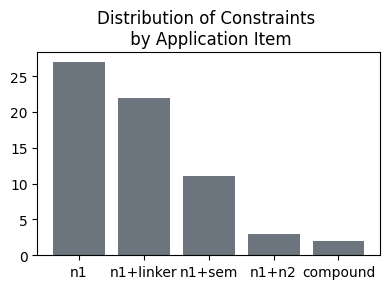

In [9]:
appl_items = [c["appl_item"] for c in constraints.values()]
counts = Counter(appl_items)
keys, values = [], []
for k, v in  sorted(counts.items(), key=lambda x: x[1], reverse=True):
    keys.append(k)
    values.append(v)

plt.figure(figsize=(4, 3))

bars = plt.bar(keys, values, color="#6c757d")

plt.title("Distribution of Constraints \n by Application Item")

plt.tight_layout()
plt.savefig(
    os.path.join(constr_stat_dir, "appl_item_distr.png"),
    dpi="figure"
)
plt.show()

Below are the counts of unique items for each item type in each dataset.

In [10]:
appl_item_counts_data = defaultdict(dict)

# TODO: optimize
for c_id, dname in product(constraints, data_specs):
    constr = constraints[c_id]
    if dname not in constr["datasets_n_appl_items"]:
        continue
    appl_item_counts_data[constr["appl_item"]][dname] = constr["datasets_n_appl_items"][dname]

appl_item_counts = pd.DataFrame(appl_item_counts_data).fillna(0).astype(int)

save_cstat_tsv(appl_item_counts, "appl_item_counts")
appl_item_counts

,compound,n1,n1+sem,n1+n2,n1+linker
gecodb_v06,282767,3614,0,0,4870
gecodb_v07,275411,3594,0,0,4743
gecodb_v07_gn,48980,3320,0,48664,3587
sp18_pl_constr,0,0,78,0,88


## 2. Inspection of Constraint Applicability

This chapter is the core part of the notebook. It analyses the application measures of the constraints, which includes their distribution and correlation, and seeks to establish relation between the values of coverage and regularity of the constraints, and their ontological properties considered in [chapter 1](#1-inspection-of-constraint-ontological-properties).

1. We start by general overview of the value distribution. We first draw a scatter plot of all item and type coverage and regularity measures obtained from the different datasets.
2. We notice that the values from the different versions of the GeCoDB dataset are strikingly close. The pairwise comparison of the values from all the versions of the GeCoDB dataset reveals that they are distributed identically and are extremely correlated. We choose to proceed with the GeCoDB_v07_GN version only since it verifies the widest range of the constraints.
3. We compare the item and the type variants of coverage and regularity and discover that they are distributed identically and are highly correlated. We choose to proceed with the item variant as the more balanced estimate.
4. At this step, we analyze the natural clustering of the item coverage and regularity values, and propose a new (ir)regularity scale.

---

**NB!** We filter out all constraints with item regularity of $<0.5$ from step 3 on.

Load statistics. In total, we have statistics for 53 constraints of different datasets.

In [11]:
stats = pd.read_csv(
    os.path.join(appl_stat_dir, "appl_statistics_summary.tsv"),
    sep="\t",
    index_col=(0, 1),
    header=0
).dropna()  # remove non-implemented constraints

stats

appl_item  n_appl_items  \
constr_id                 dataset                                   
def-0                     gecodb_v06       compound      282767.0   
                          gecodb_v07       compound      275411.0   
                          gecodb_v07_gn    compound       48980.0   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06             n1        3614.0   
                          gecodb_v07             n1        3594.0   
...                                             ...           ...   
l2p:es|mono_syl           gecodb_v07_gn   n1+linker        3587.0   
l2p:0_uml                 gecodb_v06      n1+linker        4870.0   
                          gecodb_v07      n1+linker        4743.0   
                          gecodb_v07_gn   n1+linker        3587.0   
l2p:pl_marker|def-pl      sp18_pl_constr  n1+linker          88.0   

                                                quantifier  cvg_item_abs  \
constr_id                 dataset                                          
def-0                     gecodb_v06              majority      282767.0   
                          gecodb_v07              majority      275397.0   
                          gecodb_v07_gn           majority       48976.0   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06      almost regularly         241.0   
                          gecodb_v07      almost regularly         240.0   
...                                                    ...           ...   
l2p:es|mono_syl           gecodb_v07_gn                all          36.0   
l2p:0_uml                 gecodb_v06                   all          17.0   
                          gecodb_v07                   all          15.0   
                          gecodb_v07_gn                all           5.0   
l2p:pl_marker|def-pl      sp18_pl_constr              tend          40.0   

                                          cvg_item  cvg_type  reg_item  \
constr_id                 dataset                                        
def-0                     gecodb_v06         1.000     1.000     0.578   
                          gecodb_v07         1.000     1.000     0.577   
                          gecodb_v07_gn      1.000     1.000     0.573   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06         0.067     0.066     0.954   
                          gecodb_v07         0.067     0.065     0.958   
...                                            ...       ...       ...   
l2p:es|mono_syl           gecodb_v07_gn      0.010     0.015     0.972   
l2p:0_uml                 gecodb_v06         0.003     0.000     1.000   
                          gecodb_v07         0.003     0.000     1.000   
                          gecodb_v07_gn      0.001     0.000     1.000   
l2p:pl_marker|def-pl      sp18_pl_constr     0.455     0.465     0.146   

                                          reg_type  n_violations  \
constr_id                 dataset                                  
def-0                     gecodb_v06         0.578    119391.000   
                          gecodb_v07         0.577    116588.000   
                          gecodb_v07_gn      0.573     20889.000   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06         0.936        11.047   
                          gecodb_v07         0.939        10.051   
...                                            ...           ...   
l2p:es|mono_syl           gecodb_v07_gn      0.941         1.000   
l2p:0_uml                 gecodb_v06         1.000         0.000   
                          gecodb_v07         1.000         0.000   
                          gecodb_v07_gn      1.000         0.000   
l2p:pl_marker|def-pl      sp18_pl_constr     0.153        34.159   

                                         is_productive is_regular  \
constr_id                 dataset                                   
def-0                     gecodb_v06             False      False   
                          gecodb_v07             False      False   
                          gecod

In [12]:
stat_ids = np.unique([ind[0] for ind in stats.index])
stat_ids_p2l = np.char.startswith(stat_ids, "p2l:").sum().item()
stat_ids_l2p = np.char.startswith(stat_ids, "l2p:").sum().item()
pd.Series(
    {"total": len(stat_ids), "P2L": stat_ids_p2l, "L2P": stat_ids_l2p}
).to_frame("N")

,N
total,54
P2L,36
L2P,17


In [13]:
# for more efficient processing
stats = stats.swaplevel(0, 1)

1\. Draw the plots of item and type coverage and regularity values.

In [35]:
dot_kw = {
    "facecolors": "none",   # hollow inside
    "edgecolors": "black",  # outline
    "s": 100                 # marker size
}

line_kw = {
    "color": "black",
    "linewidth": 0.75,
    "linestyle": "--",
    "alpha": 0.6
}

line_label_kw = {
    "fontsize": 7,
    "alpha": 0.8,
    "clip_on": False
}

# https://matplotlib.org/stable/api/markers_api.html#module-matplotlib.markers
markers = {
    # add with new datasets
    "gecodb_v06": "o",
    "gecodb_v07": "v",
    "gecodb_v07_gn": "*",
    "sp18_pl_constr": "p",
    # "s"
}

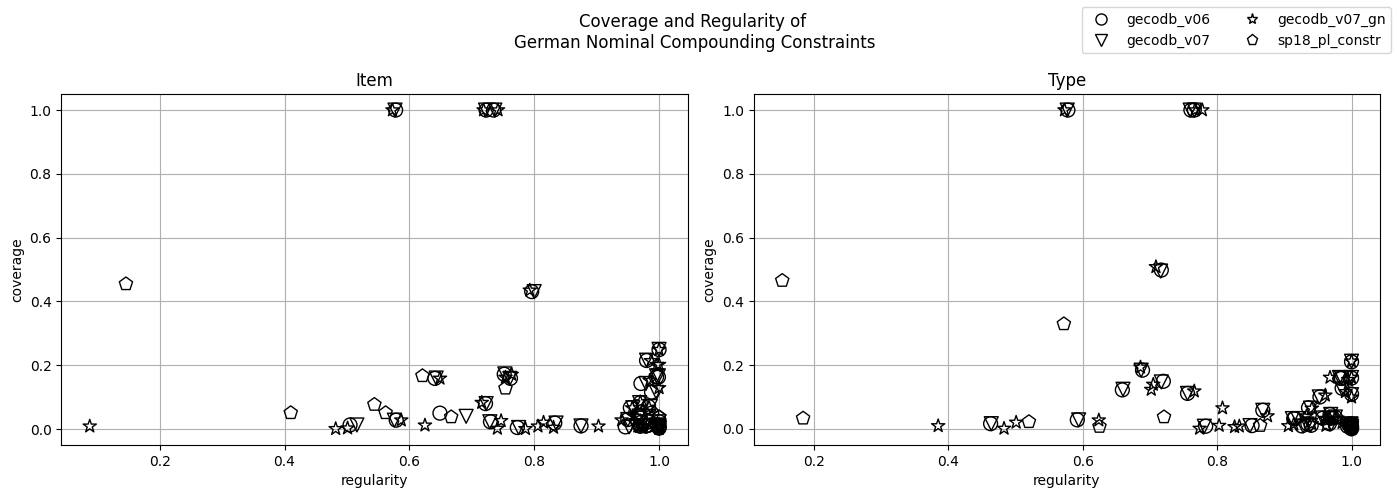

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

legend = []
for dname in data_specs:

    stats_dname = stats.loc[dname]
    marker = markers[dname]

    # item cvg/reg values
    axes[0].scatter(
        stats_dname["reg_item"],
        stats_dname["cvg_item"],
        **dot_kw,
        marker=marker
    )
    axes[0].set_xlabel("regularity")
    axes[0].set_ylabel("coverage")
    axes[0].set_title("Item")


    # type cvg/reg values
    axes[1].scatter(
        stats_dname["reg_type"],
        stats_dname["cvg_type"],
        **dot_kw,
        marker=marker
    )
    axes[1].set_xlabel("regularity")
    axes[1].set_ylabel("coverage")
    axes[1].set_title("Type")

    legend_handle = mlines.Line2D(
        [], [], color="black", marker=marker, linestyle="None",
        markersize=8, markerfacecolor="none", label=dname
    )
    legend.append(legend_handle)

for axis in axes:

    # # horizontal lines for coverage
    # for y in critical_points_cvg[1: -1]:
    #     ax.axhline(y=y, **line_kw)
    #     ax.text(
    #         1.03, y - (0.03 * (y == 0.01)), y,
    #         va="center", ha="left", **line_label_kw
    #     )

    # # vertical lines for regularity
    # for x in critical_points_reg[: -1]:
    #     ax.axvline(x=x, **line_kw)
    #     if not x in ax.get_xticks().round(2):
    #         ax.text(
    #             x, -0.1, x,
    #             va="bottom", ha="center",
    #             **line_label_kw
    #         )

    axis.set_xlim(0.1, 1.02)
    axis.set_ylim(-0.03, 1.06)
    axis.grid()
    axis.set_axisbelow(True)

fig.suptitle(
    "Coverage and Regularity of \n"
    "German Nominal Compounding Constraints"
)
fig.legend(handles=legend, loc="upper right", ncol=2)

plt.tight_layout()
plt.savefig(
    os.path.join(appl_stat_dir, "cvg_reg.png"),
    dpi="figure"
)
plt.show()

2\. One can see that almost all the values from different versions of the GeCoDB dataset are located at the same spots. For each unique pair of these versions, we run a Mann-Whitney U-test to test whether the values of item and type coverage and regularity  across the pair come from the same distribution. We additionally calculate the Pearson correlation coefficient to test for the mutual predictability of the values.

The results reveal that none of the comparisons reach a significant result of the Mann-Whitney U-test (all p-values $>0.9$; alternative hypothesis: the distributions are not identical). Moreover, the Pearson correlation coefficient approximates or reaches $1.0$ for all comparisons. We conclude that the results from different GeCoDB versions are interchangeable, and choose to proceed with GeCoDB_v07_GN as the dataset with most of verified constraints.

The fact the results from GeCoDB_v07_GN are statistically identical to the results of GeCoDB_v06 and GeCoDB_v07 provide additional evidence that the earlier datasets were and are sufficiently clean and eligible for the corpus study, and that the results of the first corpus study are valid and legitimate. While one might have argued that unexpectedly low regularity of some constraints was a result of the presence of low-quality data from the web in GeCoDB_v06 (typos, unconventional compounds, etc.), compounds from GermaNet can hardly be accused of that.

In [16]:
r = lambda x, y: x.corr(y, method="pearson")

mw_gecodb_versions_data = {}
for g0, g1 in combinations([k for k in data_specs if k.startswith("gecodb")], 2):
    corr_res = {}
    for param in [("reg", "item"), ("reg", "type"), ("cvg", "item"), ("cvg", "type")]:
        param_str = "_".join(param)
        mw = mannwhitneyu(stats.loc["gecodb_v06", param_str], stats.loc["gecodb_v07", param_str])
        corr_res[param] = {
            "U": mw.statistic,
            "p": mw.pvalue,
            "r": r(stats.loc["gecodb_v06", param_str], (stats.loc["gecodb_v07", param_str]))
        }
    mw_gecodb_versions_data[f"{g0} vs. {g1}"] = pd.DataFrame(corr_res).round(3)

mw_gecodb_versions = pd.concat(mw_gecodb_versions_data, names=["comparison"])

save_astat_tsv(mw_gecodb_versions, "mw_gecodb_versions")
mw_gecodb_versions

reg             cvg         
                                   item   type     item     type
comparison                                                      
gecodb_v06 vs. gecodb_v07    U  769.500  760.5  761.500  755.500
                             p    0.932    1.0    0.996    0.964
                             r    0.999    1.0    1.000    1.000
gecodb_v06 vs. gecodb_v07_gn U  769.500  760.5  761.500  755.500
                             p    0.932    1.0    0.996    0.964
                             r    0.999    1.0    1.000    1.000
gecodb_v07 vs. gecodb_v07_gn U  769.500  760.5  761.500  755.500
                             p    0.932    1.0    0.996    0.964
                             r    0.999    1.0    1.000    1.000

We now assemble a joint statistics dataset from GeCoDB_v07_GN and SP18_Pl_Constr. Note that for further analysis, we drop all constraints with item regularity of $<0.5$.

In [ ]:
# make sure no overlap is left
set(stats.loc["gecodb_v07_gn"].index) & set(stats.loc["sp18_pl_constr"].index)

set()

In [18]:
stats_flat = stats.loc[["gecodb_v07_gn", "sp18_pl_constr"]]    \
    .reset_index(level=0, drop=False)

stats_flat = stats_flat[stats_flat["reg_item"] >= 0.5]

stats_flat_p2l = stats_flat[stats_flat.index.str.startswith("p2l:")]
stats_flat_l2p = stats_flat[stats_flat.index.str.startswith("l2p:")]

stats_flat

,dataset,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,,
def-0,gecodb_v07_gn,compound,48980.0,majority,48976.0,1.000,1.000,0.573,0.573,20889.000,False,False,low regularity,low regularity,supported
p2l:decl_cl:pl:#0-0|def-0,gecodb_v07_gn,n1,3320.0,almost regularly,218.0,0.066,0.064,0.957,0.941,9.303,True,False,high regularity,high regularity,supported
p2l:decl_cl:pl:#s-0,gecodb_v07_gn,n1,3320.0,almost all,117.0,0.035,0.029,0.965,0.962,4.080,True,True,high regularity,regular,supported+
p2l:decl_cl:pl:#e-0|def-0,gecodb_v07_gn,n1,3320.0,mostly,537.0,0.162,0.193,0.754,0.686,131.933,False,False,low regularity,moderate regularity,supported+
p2l:decl_cl:pl:#er-0/er|def-0/er,gecodb_v07_gn,n1,3320.0,mostly,69.0,0.021,0.065,0.815,0.808,12.790,True,False,low regularity,moderate regularity,supported+
p2l:decl_cl:pl:#er-0/er|mass-interpr-0,gecodb_v07_gn,n1,3320.0,tend,6.0,0.002,0.009,0.741,0.906,1.554,True,True,moderate regularity,regular,supported+
p2l:decl_cl:pl:#er-0/er|anim-er,gecodb_v07_gn,n1,3320.0,may,10.0,0.003,0.010,0.501,0.803,4.989,False,False,low regularity,low regularity,supported
p2l:decl_cl:pl:#e_uml-0|def-0,gecodb_v07_gn,n1,3320.0,mostly,274.0,0.083,0.118,0.716,0.766,77.935,False,False,low regularity,moderate regularity,supported+
p2l:decl_cl:pl:#0_uml-0|def-0,gecodb_v07_gn,n1,3320.0,almost always,24.0,0.007,0.019,0.974,0.986,0.612,True,True,high regularity,regular,supported+


3\. The comparison of the item and type variants of the measures allows to conclude that the two variants are statistically very similar. We choose to proceed with the item variant as the more balanced version of the measures.

First, the central tendency measures between the two variants are almost identical for both coverage and regularity.

In [19]:
item_type_desc_data = {}
for param in [("reg", "item"), ("reg", "type"), ("cvg", "item"), ("cvg", "type")]:
    param_str = "_".join(param)
    item_type_desc_data[param] = stats_flat[param_str] \
        .describe(percentiles=[0.5, 0.9])

item_type_desc = pd.concat(item_type_desc_data, axis=1).T.round(3)
save_astat_tsv(item_type_desc, "item_type_desc")
item_type_desc

count   mean    std    min    50%    90%  max
reg item   50.0  0.856  0.158  0.501  0.958  1.000  1.0
    type   50.0  0.868  0.150  0.501  0.941  1.000  1.0
cvg item   50.0  0.125  0.239  0.001  0.037  0.218  1.0
    type   50.0  0.121  0.243  0.000  0.028  0.224  1.0

Furthermore, the results of the Mann-Whitney U-test suggest that the two variants of both coverage and regularity come from the same distribution (both p-values $>0.7$; alternative hypothesis: the distributions are not identical). Very high Pearson correlation coefficients ($0.988$ and $0.856$ for coverage and regularity, respectively) and very low MAEs ($0.023$ and $0.049$ for coverage and regularity, respectively) confirm that the two variants of the measures are interchangeable.

This finding numerically support the equivalent assumption from Shmalts 2026.

In [21]:
mw_item_type = pd.DataFrame({
   param: {
        "U": (mw := mannwhitneyu(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"])).statistic,
        "p": mw.pvalue,
        "r": r(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"]),
        "mae": mean_absolute_error(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"])
    }
    for param in ["cvg", "reg"]
}).round(3)

save_astat_tsv(mw_item_type, "mw_item_type")
mw_item_type

,cvg,reg
U,1250.000,1161.500
p,0.728,0.783
r,0.988,0.856
mae,0.023,0.049


4\. As readily reported in Shmalts 2026, the item coverage values are mostly very low, with more than half of constraints lying in the range of $[0.0; 0.05)$ (28 of 53).

What concerns the item regularity values, the present study also produces novel results. Specifically, it seems that the thresholds of $0.7$ and $0.9$ are the natural barriers between "low", "moderate", and "high" regularity. Indeed, the respective (ir)regularity levels are seen clearly on the scatter plot. The legitimacy of this values is further supported by the fact that they cut through the two largest gaps between neighboring item regularity values in the dataset.

The item regularity values clustering calls the original regularity scale from Shmalts 2026 into question. We propose the found thresholds as the new (ir)regularity scale. More on the completion of the new scale with the "regular" level follows.

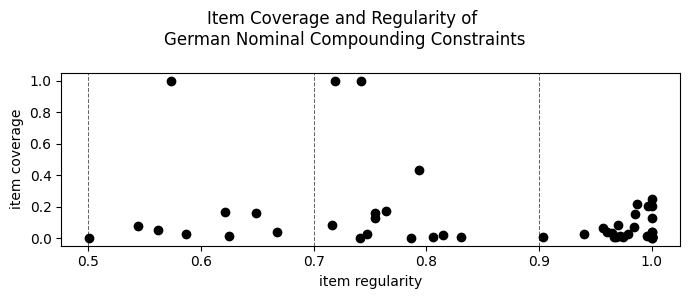

In [39]:
fig, axis = plt.subplots(1, 1, figsize=(7, 3))

critical_points_cvg = [0.0, 0.05, 0.2, 1.01]
critical_points_reg = [0.5, 0.7, 0.9, 1.01]

axis.scatter(stats_flat["reg_item"], stats_flat["cvg_item"], color="black")

# vertical lines for regularity
for x in critical_points_reg[: -1]:
    axis.axvline(x=x, **line_kw)

axis.set_xlabel("item regularity")
axis.set_ylabel("item coverage")

fig.suptitle(
    "Item Coverage and Regularity of \n"
    "German Nominal Compounding Constraints"
)

plt.tight_layout()
plt.savefig(
    os.path.join(appl_stat_dir, "cvg_reg_flat.png"),
    dpi="figure"
)
plt.show()

Interestingly, almost all L2P values have very low coverage and very high regularity, while the P2L constraints are distributed more or less evenly. This attests the equivalent finding from Shmalts 2026 and confirms its robustness after adding new constraints.

In [37]:
get_val_clusters = lambda stats, val, cp: pd.Series({
	f"{val}: [{left}-{right})": (
		(stats[f"{val}_item"] >= left) &
		(stats[f"{val}_item"] < right)
	).sum()
	for left, right in pairwise(cp)
})

cvg_clusters = pd.DataFrame(
    {
        "all": get_val_clusters(stats_flat, "cvg", critical_points_cvg),
        "P2L": get_val_clusters(stats_flat_p2l, "cvg", critical_points_cvg),
        "L2P": get_val_clusters(stats_flat_l2p, "cvg", critical_points_cvg)
    }
)

reg_clusters = pd.DataFrame(
    {
        "all": get_val_clusters(stats_flat, "reg", critical_points_reg),
        "P2L": get_val_clusters(stats_flat_p2l, "reg", critical_points_reg),
        "L2P": get_val_clusters(stats_flat_l2p, "reg", critical_points_reg)
    }
)

partition = pd.DataFrame({"all": "", "P2L": "", "L2P": ""}, index=[""] * 2)

cvg_reg_clusters = pd.concat((cvg_clusters, partition, reg_clusters))
save_astat_tsv(cvg_reg_clusters, "cvg_reg_clusters")
cvg_reg_clusters

,all,P2L,L2P
cvg: [0.0-0.05),29,17,12
cvg: [0.05-0.2),13,11,2
cvg: [0.2-1.01),8,5,2
,,,
,,,
reg: [0.5-0.7),9,8,0
reg: [0.7-0.9),13,10,3
reg: [0.9-1.01),28,15,13


The two largest gaps betwee neighboring item regularity values are $0.831$-$0.903$ and $0.667$-$0.716$. These gaps are precisely cut by the threshold of $0.9$ and $0.7$, respectively.

In [46]:
gaps = []
for r0, r1 in pairwise(stats_flat["reg_item"].sort_values()):
    diff = r1 - r0
    gaps.append({"left": r0, "right": r1, "diff": diff})
gaps = sorted(gaps, key=lambda x: x["diff"], reverse=True)
pd.DataFrame(gaps[:10])

,left,right,diff
0,0.831,0.903,0.072
1,0.667,0.716,0.049
2,0.501,0.544,0.043
3,0.903,0.940,0.037
4,0.587,0.621,0.034
5,0.625,0.649,0.024
6,0.719,0.741,0.022
7,0.764,0.786,0.022
8,0.544,0.562,0.018
9,0.649,0.667,0.018


In [24]:
corr_cvg_reg = pd.DataFrame({
    "r": {
        v: stats_flat[f"reg_{v}"].corr(stats_flat[f"cvg_{v}"], method="pearson")
        for v in ["item", "type"]
    }
}).T.round(3)

save_astat_tsv(corr_cvg_reg, "corr_cvg_reg")
corr_cvg_reg

,item,type
r,-0.267,-0.344


In [23]:
mw_p2l_l2p_data = {}
for sign, a in [("<>", "two-sided"), (">", "greater"), ("<", "less")]:
    res = pd.DataFrame({
        param: {
            f"U": (mw := mannwhitneyu(
                stats_flat_p2l[f"{param}_item"],
                stats_flat_l2p[f"{param}_item"],
                alternative=a
            )).statistic,
            f"p": mw.pvalue
        }
        for param in ["cvg", "reg"]
    })
    mw_p2l_l2p_data[f"P2L{sign}L2P"] = res
mw_p2l_l2p = pd.concat(mw_p2l_l2p_data, names=["alternative"]).round(3)

save_astat_tsv(mw_p2l_l2p, "mw_p2l_l2p")
mw_p2l_l2p

cvg      reg
alternative                    
P2L<>L2P    U  353.000  123.500
            p    0.034    0.004
P2L>L2P     U  353.000  123.500
            p    0.017    0.998
P2L<L2P     U  353.000  123.500
            p    0.984    0.002

In [25]:
ling_type_mtrx = stats_flat.apply(
    lambda row: {
        ling_type: True
        for ling_type in constraints[row.name]["ling_info_type"]
    },
    axis=1,
    result_type="expand"
)
ling_type_mtrx.fillna(False, inplace=True)
ling_type_mtrx.drop(columns=["default"], inplace=True)

In [ ]:
stats_flat = pd.concat((stats_flat, ling_type_mtrx), axis=1)
stats_flat.drop(
    # the default
    stats_flat[stats_flat.apply(
        lambda row: row[cols].sum() == 0,
        axis=1
    )].index,
    inplace=True
)
stats_flat.sample(5)

,dataset,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level,morphological,derivational,semantic,phonological,lexical
constr_id,,,,,,,,,,,,,,,,,,,,
p2l:decl_cl:pl:#er-0/er|anim-er,gecodb_v07_gn,n1,3320.0,may,10.0,0.003,0.010,0.501,0.803,4.989,False,False,low regularity,low regularity,supported,True,False,True,False,False
l2p:s|f_poly_syl,gecodb_v07_gn,n1+linker,3587.0,all,723.0,0.202,0.161,1.000,1.000,0.000,True,True,regular,regular,supported,True,False,False,True,False
l2p:e_uml,gecodb_v07_gn,n1+linker,3587.0,all,12.0,0.003,0.002,1.000,1.000,0.000,True,True,regular,regular,supported,True,False,False,False,False
l2p:er|smpx,gecodb_v07_gn,n1+linker,3587.0,most,31.0,0.009,0.014,0.903,0.914,3.000,True,True,low regularity,regular,supported+,False,True,False,False,False
l2p:s|smpx_mn,gecodb_v07_gn,n1+linker,3587.0,almost all,95.0,0.026,0.040,0.979,0.875,2.000,True,True,high regularity,regular,supported+,True,False,False,False,False


In [27]:
# https://matplotlib.org/stable/gallery/color/named_colors.html
colors = {
    "morphological": "red",
    "derivational": "green",
    "phonological": "blue",
    "semantic": "gold",
    "lexical": "blueviolet"
}
matplotlib.rcParams["hatch.linewidth"] = 2.0

def get_dots(ling_types: List[str], marker: str) -> dict:
    ling_types = sorted(ling_types)
    match len(ling_types):
        case 1:
            dots = [{
                "facecolors": colors[ling_types[0]],
                
                "marker": marker
            }]
        case 2:
            # two halves
            dots = [
                {
                    "facecolors": colors[ling_types[0]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="left"
                    )
                },
                {
                    "facecolors": colors[ling_types[1]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="right"
                    )
                }
            ]
        case 3:
            # two halves + hatch
            dots = [
                {
                    "facecolors": colors[ling_types[0]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="left"
                    )
                },
                {
                    "facecolors": colors[ling_types[1]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="right"
                    )
                },
                {
                    "facecolors": "none",
                    "edgecolors": colors[ling_types[2]],
                    "hatch": "////",
                    "marker": marker
                }
            ]
        case _:
            raise NotImplemented
    return dots    

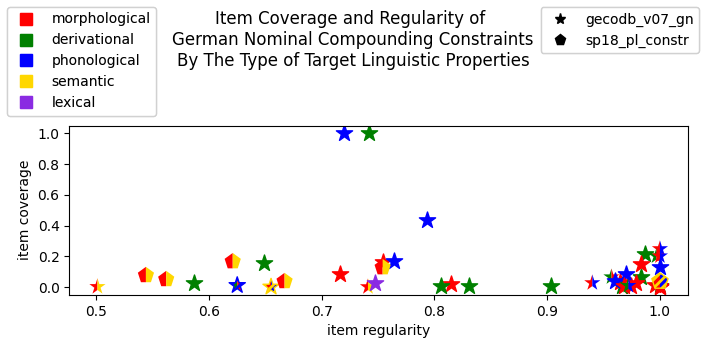

In [28]:
fig, axis = plt.subplots(1, 1, figsize=(7, 3.5))

for c_id, row in stats_flat.iterrows():

    if c_id == "def-0":
        continue

    marker = markers[row["dataset"]]
    dots = get_dots(constraints[c_id]["ling_info_type"], marker)
    for dot in dots:
        axis.scatter(
            row["reg_item"],
            row["cvg_item"],
            s=150,
            **dot
        )

axis.set_xlabel("item regularity")
axis.set_ylabel("item coverage")

legend_dataset = [
    mlines.Line2D(
        [], [], color="black", marker=markers[dname], linestyle="None",
        markersize=8, markerfacecolor="black", label=dname
    )
    for dname in stats_flat["dataset"].unique()
]
legend_colors = [
    mlines.Line2D(
        [], [], color=color, marker="s", linestyle="None",
        markersize=8, markerfacecolor=color, label=ling_type
    )
    for ling_type, color in colors.items()
    if ling_type in stats_flat
]

fig.suptitle(
    "Item Coverage and Regularity of \n"
    "German Nominal Compounding Constraints\n"
    "By The Type of Target Linguistic Properties"
)
legc = fig.legend(handles=legend_colors, loc="upper left")
legd = fig.legend(handles=legend_dataset, loc="upper right")
axis.add_artist(legc)
axis.add_artist(legd)

plt.tight_layout()
plt.subplots_adjust(top=0.65)
plt.savefig(
    os.path.join(appl_stat_dir, "cvg_reg_vs_ling_type.png"),
    dpi="figure"
)
plt.show()

In [29]:
# X = stats_flat[["morphological", "derivational", "phonological", "semantic"]]
# y = {
#     "cvg": stats_flat["cvg_item"],
#     "reg": stats_flat["reg_item"]
# }

# lr_cvg_reg_vs_ling_type_data = {}
# for param in ["cvg", "reg"]:
#     lr = LinearRegression(positive=False)
#     lr.fit(X, y[param])
#     lr_cvg_reg_vs_ling_type_data[param] = {
#         "intercept": lr.intercept_,
#         **{
#             f"coef_{ling_type}": lr.coef_[i]
#             for i, ling_type in enumerate(X.columns)
#         }
#     }

# lr_cvg_reg_vs_ling_type = pd.DataFrame(lr_cvg_reg_vs_ling_type_data)
# save_astat_tsv(lr_cvg_reg_vs_ling_type, "lr_cvg_reg_vs_ling_type")
# lr_cvg_reg_vs_ling_type

In [30]:
# the same as above but more informative:
ols = smf.ols(f"cvg_item ~ {' + '.join(cols)} + 1", data=stats_flat).fit()
with open(os.path.join(appl_stat_dir, "lr_cvg_vs_ling_type.txt"), "w") as out:
    out.write(str(ols.summary()))
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:               cvg_item   R-squared:                       0.117
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     1.109
Date:                Thu, 30 Jul 2026   Prob (F-statistic):              0.370
Time:                        13:41:17   Log-Likelihood:                 10.977
No. Observations:                  48   AIC:                            -9.954
Df Residuals:                      42   BIC:                             1.273
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.24

In [31]:
ols = smf.ols(f"reg_item ~ {' + '.join(cols)} + 1", data=stats_flat).fit()
with open(os.path.join(appl_stat_dir, "lr_reg_vs_ling_type.txt"), "w") as out:
    out.write(str(ols.summary()))
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:               reg_item   R-squared:                       0.305
Model:                            OLS   Adj. R-squared:                  0.222
Method:                 Least Squares   F-statistic:                     3.684
Date:                Thu, 30 Jul 2026   Prob (F-statistic):            0.00746
Time:                        13:41:17   Log-Likelihood:                 29.897
No. Observations:                  48   AIC:                            -47.79
Df Residuals:                      42   BIC:                            -36.57
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.85

Note that all non-confirmed constraints are semantic as well => the real picture is more severe

## 4. Inspection of The Extent to Which the Claims About the Constraints Made in The Literature Are Supported by The Data

The following steps are to be done for final inspection:
1. Manually inspect the support level of the claims in the empirical data. For each (analyzed) constraint, record the level of support. Since the definitions are mostly vague, base the decision on commonsense judgments. For the support level, we concentrate on the type variant of the measures since we focus on the linguistic side of the question (not real usage). There are 4 levels of support:
    * Supported. Full or very close correspondence between the quantifier and the empirical data. Examples: "regular" vs 0.99, "mostly" vs 0.75.
    * Partially supported. The gap is not critical yet noticeable. Examples: "regular" vs 0.93, "tends" vs 0.6, "sometimes" vs 0.9.
    * Not supported. The discrepancy between the quantifier and the empirical data is too significant to ignore. Examples: "regular" vs 0.85, "tends" vs 0.4.
    * NA: no data available (unreliable or semantic/lexical constraints).

Note: this steps is being conducted in the file with constraints definitions, see `constraints/constraints.yaml`. While it is being now made at the time of this inspection, we cannot reflect this processes here. After this step is done, we pull the results from this file and further inspect them in detail, specifically:

2. Inspect the distribution of the support levels.
3. Manually inspect the constraints that are only partially supported by the data or not supported at all.

### 4.1. Inspection of The Support Level

Done separately in `constraints/constraints.yaml`.

NEW SCALE:

0.5, 0.6, 0.8, 0.95 | regular

In [32]:
# # Yang 2016: 67
# 23 is an error in the original table,
# see Yang 2016: 62
# 100 / ln(100) ~= 21.715
yang_values = [10, 20, 50, 100, 200, 500, 1000, 5000]
irreg_tp_values_data = {
    "TP": {
        n: REGULARITY_SCALE._yang_theta(n)
        for n in yang_values
    },
    "ITP": {
        n: 1 - REGULARITY_SCALE._reg_tolerance(n)
        for n in yang_values
    }
}
irreg_tp_values = pd.DataFrame(irreg_tp_values_data)
irreg_tp_values["TP"] = irreg_tp_values["TP"].astype(int)
irreg_tp_values["ITP"] = irreg_tp_values["ITP"].round(3)
save_astat_tsv(irreg_tp_values, "irreg_tp_values")
irreg_tp_values

,TP,ITP
10,4,0.770
20,6,0.850
50,12,0.922
100,21,0.954
200,37,0.974
500,80,0.988
1000,144,0.993
5000,587,0.998


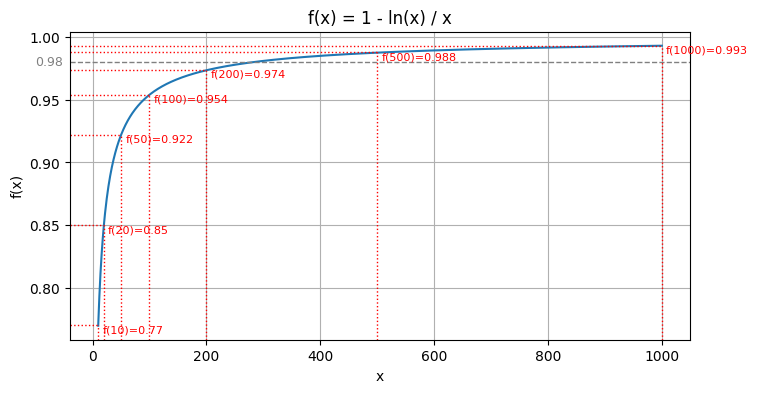

In [33]:
x = np.arange(10, 1001)
y = 1 - np.log(x) / x

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(x, y)

# draw the old threshold
for x in [0.98]:
    ax.axhline(y=x, color="grey", linestyle="--", linewidth=1)
    ax.text(
        -100, x, x,
        va="center", ha="left", color="grey", fontsize=9
    )

# draw new threshold examples
for x, y in irreg_tp_values["ITP"].items():
    if x > 1000:
        continue
    x_max, y_max = ax.transAxes.inverted().transform(ax.transData.transform((x, y)))
    ax.axvline(x=x, ymax=y_max, color="red", linewidth=1, linestyle=":")
    ax.axhline(y=y, xmax=x_max, color="red", linewidth=1, linestyle=":")
    ax.text(x + 7.5, y - 0.0075, f"f({x})={y}", color="red", fontsize=8, va="bottom", ha="left")

plt.xlabel("x")
plt.ylabel("f(x)")

plt.title("f(x) = 1 - ln(x) / x")
plt.grid(True)
plt.savefig(
    os.path.join(appl_stat_dir, "irreg_threshold.png"),
    dpi="figure"
)
plt.show()

### 4.2. Inspection of Support Level Distribution

Now, we read the constraint definition file for inspection.

In [34]:
support_levels = pd.DataFrame({
    dname: {
        sl: (stats.loc[dname]["support_level"] == sl).sum()
        for sl in stats["support_level"].unique()
    }
    for dname in data_specs
})

save_astat_tsv(support_levels, "support_levels")
support_levels

,gecodb_v06,gecodb_v07,gecodb_v07_gn,sp18_pl_constr
supported,25,26,27,3
supported+,12,12,13,4
not supported,0,0,3,2
partially supported,2,1,1,0


In [ ]:
constrs_by_itp = stats_flat.groupby(["is_productive", "is_regular"]).size() \
    .to_frame("N")

save_astat_tsv(constrs_by_itp, "constrs_by_itp")
constrs_by_itp

N
is_productive is_regular    
False         False       11
True          False       14
              True        23

In [36]:
unprod_constr = stats_flat[~stats_flat["is_productive"].astype(bool)]	\
	[["cvg_item_abs", "n_violations", "reg_item", "actual_reg_level"]]

unprod_constr.insert(
	1, "n_violations_allowed",
	unprod_constr["cvg_item_abs"].map(
		REGULARITY_SCALE._yang_theta
	).round(3)
)

save_astat_tsv(unprod_constr, "unprod_constr")
unprod_constr

,cvg_item_abs,n_violations_allowed,n_violations,reg_item,actual_reg_level
constr_id,,,,,
p2l:decl_cl:pl:#e-0|def-0,537.0,85.428,131.933,0.754,moderate regularity
p2l:decl_cl:pl:#er-0/er|anim-er,10.0,4.343,4.989,0.501,low regularity
p2l:decl_cl:pl:#e_uml-0|def-0,274.0,48.814,77.935,0.716,moderate regularity
p2l:drv:deverb_schwa$-0|def-0,94.0,20.690,38.801,0.587,low regularity
p2l:drv:prx_deverb-s,527.0,84.089,184.806,0.649,moderate regularity
p2l:phon_fin:F_stem_#t$-s,41.0,11.041,15.386,0.625,moderate regularity
p2l:phon_fin:schwa$-en|def-en,569.0,89.693,134.177,0.764,moderate regularity
p2l:tend:cmpx_morph-s|def-s,3320.0,409.486,855.716,0.742,moderate regularity
p2l:tend:cmpx_phon-s|def-s,3320.0,409.486,931.185,0.720,moderate regularity


### 4.3. Qualitative Inspection of Partially / Not Supported Constraints

Partially supported constraints.

In [55]:
def load_appl_index(dname):
    return pd.read_csv(
        os.path.join(appl_stat_dir, dname, "appl_index.tsv"),
        sep="\t",
        header=0,
        index_col="comp_gecodb",
        dtype=defaultdict(
            # to be able to parse NAs in boolean columns
            lambda: "boolean[pyarrow]",
            comp_gecodb=str,
            **{
                f"{c_id}_item": str
                for c_id in constraints
            }
        )
    )

def inspect_constr_appl(
    appl_index: pd.DataFrame, c_id: str,  only_violations: bool=True
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    # subsample the dataset stats
    sample = appl_index[
        # only covered compounds
        appl_index[c_id + "_is_applicable"]][[
        # only constraint_related columns 
        c_id + "_item", c_id + "_applies"
    ]]
    items = sample[c_id + "_item"].unique()
    example_dfs = []
    for item in items:
        # all compounds built with the item
        item_sample = sample[sample[c_id + "_item"] == item]
        Nbwi_total = len(item_sample)
        # exceptions built with the item
        item_sample_exc = item_sample[~(item_sample[c_id + "_applies"])]    \
            .drop(columns=[c_id + "_applies"])
        Nbwi_exc = len(item_sample_exc)
        perc_exc = round(Nbwi_exc / Nbwi_total, 3)
        if not only_violations:
            examples = item_sample.sample(1)
        else:
            if not len(item_sample_exc):
                continue
            examples = item_sample_exc.sample(1)
        examples[["Nbwi_total", "Nbwi_exc", "%_exc"]] = Nbwi_total, Nbwi_exc, perc_exc
        example_dfs.append(examples)
    example_df = pd.concat(example_dfs, axis=0)
    sort_by = "Nbwi_total" if not only_violations else "Nbwi_exc"
    example_df.sort_values(by=sort_by, inplace=True, ascending=False)
    return sample, example_df

In [56]:
to_inspect = []
for dname, dataset in datasets.items():

	out_dir = os.path.join(appl_stat_dir, dname, "unsupported_constr")
	os.makedirs(out_dir, exist_ok=True)

	appl_index = load_appl_index(dname)

	is_unsup = stats.loc[dname, "support_level"].isin(["partially supported", "not supported"])
	unsupported_constr = stats.loc[dname].loc[is_unsup]
	save_tsv(unsupported_constr, os.path.join(out_dir, "constr_list.tsv"))

	violations = []
	for c_id in unsupported_constr.index:
		sample, examples = inspect_constr_appl(appl_index, c_id)
		sample = dataset.loc[sample.index]
		c_id_alias = constraints[c_id]["func_alias"]	# avoid "/"s in ids
		save_tsv(sample, os.path.join(out_dir, f"{c_id_alias}_sample.tsv"))
		save_tsv(examples, os.path.join(out_dir, f"{c_id_alias}_summary.tsv"))
		violations.append(examples)

	to_inspect.append((unsupported_constr, violations))

GeCoDB_v06

In [57]:
unsupported_constr, violations = to_inspect[0]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:drv:sfx:sfx-s|def-s,n1,3614.0,regularly,777.0,0.215,0.158,0.980,0.985,15.267,True,False,regular,high regularity,partially supported
l2p:n,n1+linker,4870.0,all,564.0,0.116,0.109,0.988,1.000,7.000,True,False,regular,high regularity,partially supported


In [58]:
# 121 N1s, 21 N1s that build ten or more exceptions;
# cumulative number of violations 15.267 with
# the number of covered items 777, which would
# require item regularity of 0.991
violations[0]

,p2l:drv:sfx:sfx-s|def-s_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
generation_+en_garten,generation,123,89,0.724
minderheit_+en_volk,minderheit,86,50,0.581
wirtschaft_vertreter,wirtschaft,683,49,0.072
spezialität_+en_händler,spezialität,33,33,1.000
süßigkeit_+en_verbot,süßigkeit,26,26,1.000
...,...,...,...,...
genehmigung_verfahren,genehmigung,78,1,0.013
kompression_strumpf,kompression,20,1,0.050
kleidung_stück,kleidung,58,1,0.017


In [59]:
# several mysanalyses (removed in GeCoDB_v07) => ignore
violations[1]

,l2p:n_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
mittel_+n_dorf,mittel+en,2,2,1.0
nachbar_+n_land,nachbar+en,1,1,1.0
zwiebel_+n_schneide,zwiebel+en,1,1,1.0
windel_+n_wechsel,windel+en,1,1,1.0
vokabel_+n_pauke,vokabel+en,1,1,1.0
waffel_+n_backe,waffel+en,1,1,1.0
semmel_+n_knödel,semmel+en,1,1,1.0


GeCoDB_v07

In [60]:
unsupported_constr, violations = to_inspect[1]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:drv:sfx:sfx-s|def-s,n1,3594.0,regularly,777.0,0.216,0.16,0.98,0.985,15.209,True,False,regular,high regularity,partially supported


In [61]:
# 121 N1s, 21 N1s that build ten or more exceptions;
# cumulative number of violations 15.209 with
# the number of covered items 777, which would
# require item regularity of 0.991
violations[0]

,p2l:drv:sfx:sfx-s|def-s_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
generation_+en_kluft,generation,120,86,0.717
minderheit_+en_veranstaltung,minderheit,84,49,0.583
wirtschaft_förderung,wirtschaft,674,48,0.071
spezialität_+en_angebot,spezialität,33,33,1.000
süßigkeit_+en_händler,süßigkeit,26,26,1.000
...,...,...,...,...
festung_sturm,festung,61,1,0.016
genehmigung_verfahren,genehmigung,77,1,0.013
kompression_strumpf,kompression,20,1,0.050


GeCoDB_v07_GN

In [62]:
unsupported_constr, violations = to_inspect[2]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:decl_cl:pl:#e-0|msyl_anim-e,n1,3320.0,irregularly,31.0,0.009,0.009,0.088,0.385,28.276,False,False,low regularity,below scale,not supported
p2l:drv:sfx:sfx-s|def-s,n1,3320.0,regularly,710.0,0.214,0.154,0.987,0.995,9.273,True,False,regular,high regularity,partially supported
p2l:sem:2const_anim/pers-s,n1+n2,48664.0,tend,28.0,0.001,0.001,0.482,0.483,14.500,False,False,moderate regularity,below scale,not supported
l2p:en|non_par_m,n1+linker,3587.0,all,6.0,0.002,0.001,0.655,0.750,2.071,True,False,regular,moderate regularity,not supported


In [63]:
# a few fish, birds, non-domesticated animals;
# however, domesticated animals seem to be violating
# the constraint quite often, too: there are occurrences
# of 'Hund', 'Schwein', 'Schaf', 'Stier', 'Ross'
violations[0]

,p2l:decl_cl:pl:#e-0|msyl_anim-e_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
fisch_händler,fisch,83,83,1.000
krebs_station,krebs,27,27,1.000
schaf_milch,schaf,22,22,1.000
hirsch_art,hirsch,16,16,1.000
wal_knochen,wal,12,12,1.000
schwein_+s_wal,schwein,43,10,0.233
schmetterling_+s_flügel,schmetterling,9,9,1.000
lachs_fisch,lachs,7,7,1.000
stier_hoden,stier,7,7,1.000


In [ ]:
# 14 N1s, cumulative number of violations 9.273 with
# the number of covered items 710, which would
# require item regularity of 0.991
violations[1]

,p2l:drv:sfx:sfx-s|def-s_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
minderheit_+en_regierung,minderheit,18,10,0.556
generation_+en_aufgabe,generation,8,7,0.875
nation_+en_bildung,nation,4,3,0.750
kalium_salz,kalium,3,3,1.000
nationalität_+en_frage,nationalität,3,3,1.000
gesundheit_scheck,gesundheit,97,2,0.021
priorität_+en_setzung,priorität,3,2,0.667
spezialität_+en_restaurant,spezialität,2,2,1.000
kuriosität_+en_sammlung,kuriosität,2,2,1.000


In [ ]:
# all violations seem to have been defeated
# by another constraints: mostly the
# -er suffix ot -e code constraints
violations[2]

,p2l:sem:2const_anim/pers-s_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
kind_+er_frau,kind+frau,1,1,1.0
bürger_tochter,bürger+tochter,2,1,0.5
kontakt_mann,kontakt+mann,1,1,1.0
spieler_frau,spieler+frau,1,1,1.0
arzt_tochter,arzt+tochter,1,1,1.0
arbeiter_frau,arbeiter+frau,1,1,1.0
kaiser_tochter,kaiser+tochter,1,1,1.0
schütze_+n_frau,schütze+frau,1,1,1.0
unternehmer_frau,unternehmer+frau,1,1,1.0


In [ ]:
# 
violations[3]

,l2p:en|non_par_m_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
dorn_+en_busch,dorn+en,6,6,1.000
stern_+en_kranz,stern+en,14,1,0.071
kaper_+n_strauch,kaper+en,1,1,1.000


SP18_Pl_Constr

In [67]:
unsupported_constr, violations = to_inspect[3]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:phon_fin:weak_F_cons$-0/s/en|!pl_interpr-0/s,n1+sem,78.0,mostly,4.0,0.051,0.033,0.410,0.184,2.359,True,False,low regularity,below scale,not supported
l2p:pl_marker|def-pl,n1+linker,88.0,tend,40.0,0.455,0.465,0.146,0.153,34.159,False,False,moderate regularity,below scale,not supported


In [69]:
# only four items covered in total
violations[0]

,p2l:phon_fin:weak_F_cons$-0/s/en|!pl_interpr-0/s_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
person_+en_wagen,person+sgsem,46,44,0.957
schwester_+n_konvent,schwester+sgsem,22,12,0.545
nation_+en_grenze,nation+sgsem,7,6,0.857


In [70]:
# productive violation
violations[1]

,l2p:pl_marker|def-pl_item,Nbwi_total,Nbwi_exc,%_exc
comp_gecodb,,,,
sonne_+n_brille,sonne+en,53,53,1.000
kind_+er_kanal,kind+er,59,53,0.898
hund_+e_sport,hund+e,55,51,0.927
katze_+n_haar,katze+en,50,50,1.000
bad_+=er_landschaft,"bad+""er",53,47,0.887
ei_+er_erzeugung,ei+er,47,46,0.979
frau_+en_emanzipation,frau+en,61,45,0.738
person_+en_gesellschaft,person+en,58,44,0.759
weg_+e_decke,weg+e,50,44,0.880


# Appendix

Formatting the constraints file.